# Entrenamiento por experimento: LeNet-5 y MobileNetV1

La investigación requiere **12 experimentos**, pero este notebook entrena **uno por ejecución**. Conservar la misma `SUITE` entre sesiones permite acumular los resultados de trials completos. Ejecutar todas las celdas entrena un solo trial y deja test pendiente.

Las explicaciones, diagramas y guía de ejecución están incluidos en las celdas de este notebook. La adaptación de los códigos RBF está documentada para revisión con el profesor.

In [20]:
from pathlib import Path
import json
import os
import subprocess
import sys

import pandas as pd
import torch
import wandb
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
            if (p / 'ai/src/train.py').is_file())
AI = ROOT / 'ai'
DATA_ENV = os.environ.get('SPEECH_COMMANDS_TRAINING_DATA_DIR')
if DATA_ENV:
    DATA_DIR = Path(DATA_ENV).resolve()
else:
    exports = sorted(p for p in (AI / 'data/processed/speech_commands').glob('*')
                     if p.is_dir() and (p / 'COMPLETED.json').is_file() and (p / 'preprocessing.json').is_file()
                     and len(json.loads((p / 'preprocessing.json').read_text(encoding='utf-8'))['classes']) == 11)
    if not exports:
        raise FileNotFoundError('Primero exporte las once clases con el notebook 01 o configure SPEECH_COMMANDS_TRAINING_DATA_DIR')
    DATA_DIR = exports[-1]
CONFIG = AI / 'configs/experiments.json'
PROJECT = os.environ.get('WANDB_PROJECT', 'onnxmobile-speech-commands')
ENTITY = os.environ.get('WANDB_ENTITY')
WANDB_MODE = os.environ.get('WANDB_MODE', 'online')  # online u offline; tracking obligatorio
SUITE = AI / 'runs/speech_commands_gpu_fixed_epochs_v5'  # Suite nueva: todas las épocas de cada trial
EXPERIMENT = 'lenet5-base-adam_b32_e15'  # None = siguiente pendiente; o 'lenet5-base-adam_b32_e15'
RUN_TEST = False  # Habilitar cuando quiera evaluar los cuatro ganadores
DEVICE = 'cuda'
if (SUITE / 'suite.json').exists():
    saved = json.loads((SUITE / 'suite.json').read_text(encoding='utf-8'))
    DATA_DIR = Path(json.loads((SUITE / 'dataset.json').read_text(encoding='utf-8'))['root'])
    PROJECT, ENTITY, WANDB_MODE = saved['project'], saved['entity'], saved['wandb_mode']
print('Suite:', SUITE)
print('Experimento:', EXPERIMENT or 'siguiente pendiente')
print('Datos:', DATA_DIR)
print('PyTorch:', torch.__version__, '| CUDA disponible:', torch.cuda.is_available())
print('W&B:', PROJECT, '| entidad:', ENTITY, '| modo:', WANDB_MODE)

Suite: d:\Repos\OnnxMobile\ai\runs\speech_commands_gpu_fixed_epochs_v5
Experimento: lenet5-base-adam_b32_e15
Datos: d:\Repos\OnnxMobile\ai\data\processed\speech_commands\20261014T151600309213Z
PyTorch: 2.5.1+cu121 | CUDA disponible: True
W&B: onnxmobile-speech-commands | entidad: None | modo: online


## Arquitecturas y decisiones

### Implementación manual

Ambas redes están escritas manualmente con `torch.nn` y operaciones de PyTorch.
No se usan torchvision, timm, Lightning, modelos preentrenados ni constructores
de arquitecturas externos. Se entrenan desde cero para las once clases del notebook.

### Modelo A: LeNet-5

Referencia: LeCun, Bottou, Bengio y Haffner (1998),
[Gradient-Based Learning Applied to Document Recognition](https://bottou.org/papers/lecun-98h),
DOI: 10.1109/5.726791, sección II y tabla I.

```mermaid
flowchart TD
    A["Log-Mel: N × 1 × 64 × 101"] --> R["Reescalado bilineal a 32 × 32"]
    R --> C1["C1: Conv 5×5, 1→6; 28×28; tanh escalada"]
    C1 --> S2["S2: suma 2×2, escala y sesgo entrenables; 14×14; tanh escalada"]
    S2 --> C3["C3: Conv 5×5 parcial, 6→16; 10×10; tanh escalada"]
    C3 --> S4["S4: suma 2×2, escala y sesgo entrenables; 5×5; tanh escalada"]
    S4 --> C5["C5: Conv 5×5, 16→120; 1×1; tanh escalada"]
    C5 --> F6["F6: Linear 120→84; tanh escalada"]
    F6 --> O["11 RBF euclidianas; logits = −distancia²"]
```

Se mantienen los anchos 6/16/120/84, kernels 5×5, conectividad parcial original de
C3 (1.516 parámetros), subsampling con escala y sesgo aprendibles y activación
`1.7159 tanh(2x/3)`. El núcleo suma **60.000 parámetros entrenables**.
La entrada log-Mel se interpola a 32×32, un canal, sin ejes ni color. Esto reduce
resolución temporal/espectral y debe discutirse como limitación de la adaptación.
La interpolación está dentro del forward para que ambas redes reciban el mismo
contrato de entrada `N×1×64×101`.

La salida conserva la distancia RBF de 84 componentes. El artículo usa códigos
fijos ±1 de glifos de dígitos: para audio se necesitan once códigos de palabras.
Se emplean códigos binarios distintos y reproducibles con semilla fija 1998,
guardados como buffers del checkpoint. **El cambio de diez glifos a once códigos
de audio se debe consultar al profesor antes de presentar esta adaptación como
aprobada.** Aquí se explicita la decisión para permitir esa revisión; no se
presupone aprobación. La pérdida discriminativa es cross-entropy sobre las
distancias negativas, no la función MAP específica del artículo. El enunciado
solicita definir la pérdida; reportar esta elección expresamente.

No se reemplazan subsampling por max pooling, C3 parcial por convolución densa,
tanh por ReLU ni RBF por una capa lineal. Si el profesor solicita una variante
didáctica distinta, documentar y aprobar sus cambios antes de compararla.

### Modelo B: MobileNetV1 α=0,25

Referencia: Howard et al. (2017),
[MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications](https://arxiv.org/abs/1704.04861),
tabla 1. Se implementa el orden de los trece bloques separables del artículo y
su multiplicador de ancho. Los anchos reales son 8/16/32/64/128/256.

```mermaid
flowchart TD
    A["Log-Mel: N × 1 × 64 × 101"] --> C["Conv 3×3 s2: 1→8; BN + ReLU; 32×51"]
    C --> B1["DW3×3 s1 + PW1×1: 8→16; 32×51"]
    B1 --> B2["DW s2 + PW: 16→32; 16×26"]
    B2 --> B3["DW s1 + PW: 32→32; 16×26"]
    B3 --> B4["DW s2 + PW: 32→64; 8×13"]
    B4 --> B5["DW s1 + PW: 64→64; 8×13"]
    B5 --> B6["DW s2 + PW: 64→128; 4×7"]
    B6 --> B7["5 × (DW s1 + PW: 128→128); 4×7"]
    B7 --> B8["DW s2 + PW: 128→256; 2×4"]
    B8 --> B9["DW s1 + PW: 256→256; 2×4"]
    B9 --> G["Global average pooling: 256"]
    G --> O["Linear 256→11; logits"]
```

Cada DW es `Conv2d(groups=in_channels)`. Cada DW/PW usa batch normalization y
ReLU. La convolución inicial admite un canal; el clasificador admite once clases.
Para un kernel K×K, M entradas, N salidas y D posiciones, la convolución estándar
requiere aproximadamente `K²MND` MACs; una separable requiere `K²MD + MND`.
El ancho α reduce los términos de convoluciones puntuales aproximadamente como
α². Se conserva profundidad, se reduce ancho y se evita un clasificador denso
grande mediante pooling global. Esto motiva su uso móvil; menor costo teórico
no garantiza menor latencia en cada backend o dispositivo.

La menor capacidad puede limitar el ajuste y la generalización. BatchNorm y
weight decay ayudan a estabilizar/regularizar, pero las curvas y métricas por
clase deben sustentar las conclusiones. La selección final combina calidad y
medidas de eficiencia; probar ONNX en el teléfono es una etapa posterior.

### Datos base y aumentados

El notebook genera log-Mel 64×101×1 a partir de audio mono 16 kHz de un segundo.
Los tensores son float32 en [0,1]; no se vuelven a comprimir leyendo PNG.
Las dos variantes conservan **exactamente las mismas particiones** de hablantes.
Base entrega los N tensores originales. Aumentado entrega un train separado de
3N tensores: los N originales más dos copias independientes por ejemplo, guardadas
una sola vez. Cada copia recibe dos máscaras de frecuencia de ancho uniforme
entre 1 y 8 bandas y dos de tiempo entre 1 y 10 frames. El inicio es uniforme entre
posiciones válidas. La política está en `augmentation` de `experiments.json`;
`copies_per_sample: 2` fija el crecimiento a 3×. Cero representa el piso espectral
de −80 dB respecto al máximo del clip. No se generan variantes de validación/test.

En el espectrograma el eje horizontal es tiempo, el vertical es frecuencia Mel,
y la intensidad/color representa energía normalizada. Time masking borra franjas
verticales y frequency masking franjas horizontales. Time warping deformaría el
eje temporal del espectrograma; no es un cambio directo del eje de frecuencias.

Referencia: Park et al. (2019),
[SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition](https://arxiv.org/abs/1904.08779).
Se adopta su enmascaramiento temporal/espectral, **sin time warping**. Los anchos
son una política moderada propia para clips de un segundo, no una reproducción
de las políticas de ASR del artículo. El supuesto es que borrar una región local
conserva suficiente evidencia de la palabra y reduce dependencia de posiciones
concretas. Debe comprobarse comparando base/aumentado y errores por clase.
Se guardan tensores, etiquetas, política, semilla, hashes, código del generador,
un manifiesto con el índice original de cada copia y `preview.png`. Cada trial
aumentado lee exactamente la misma exportación, sin volver a enmascararla.
Con N=83.150, train aumentado tiene 249.450 ejemplos; el tensor ocupa unos 6,45 GB
adicionales. El dataset original permanece disponible para entrenar la base.

### Pérdida, optimización y doce experimentos

Ambas redes usan cross-entropy sin pesos de clase y muestreo controlado **solo
en train**: 20 % unknown y 80 % comandos, con igual cuota por comando. Cada
comando alcanza el tamaño del comando mayor, recorriendo sus ejemplos antes de
repetir. Unknown se vuelve a muestrear cada época, proporcionalmente por palabra
original (`source_label`); el redondeo mantiene la suma de cuotas. Los batches se
mezclan aleatoriamente; las cuotas son por época. El notebook 02 justifica la
receta, muestra conteos efectivos y el compromiso entre rechazos y activaciones
incorrectas. El 20 % es una hipótesis para validar, no una proporción óptima probada.
La configuración rechaza combinar este muestreo con pesos de frecuencia inversa.
Como alternativa, `sampling.strategy=none` permite cross-entropy ponderada con
`w_c = N_train / (C × n_c_train)`. La loss registrada acumula numeradores y
denominadores de todos los lotes, evitando promediar incorrectamente las medias.
Accuracy, macro-F1, balanced accuracy y precision/recall/F1 por clase se reportan
sin ponderar por esos pesos. Macro-F1 incluye las once clases y guía selección.

| Trial | Optimizador | LR | Batch | Épocas | Weight decay | Momentum |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| adam_b32_e15 | Adam | 0,001 | 32 | 15 | 0 | — |
| adam_b64_e30 | Adam | 0,0003 | 64 | 30 | 0,0001 | — |
| sgd_b128_e45 | SGD | 0,02 | 128 | 45 | 0,0005 | 0,95 |

Los perfiles exploran un batch pequeño con presupuesto corto, Adam con mayor
regularización y presupuesto medio, y SGD con momentum alto y presupuesto largo.
No se presupone que alguno mejore el resultado. Cada perfil se repite con los
mismos hiperparámetros en ambas arquitecturas y en base/aumentado. Se mantienen
semilla, particiones, pesos de clase, capacidad de las redes y política de aumento.
Al variar varios parámetros a la vez se comparan recetas completas; no se puede
atribuir un cambio de rendimiento a un único hiperparámetro.

Producto cartesiano: LeNet-5/MobileNetV1 × base/aumentado × tres trials = **12**.
Se ejecuta un trial por invocación de forma predeterminada, acumulando resultados
en una carpeta compartida. Cada trial se entrena de corrido en un único run W&B;
al terminar se guarda su mejor checkpoint. Los trials completos se conservan
entre sesiones, que pueden repartirse en días distintos.
Cada trial ejecuta todas sus épocas configuradas (tabla anterior), sin early stopping.
Los campos globales de `experiments.json` son defaults para trials sin overrides;
el entrenador valida la configuración efectiva después de combinar ambos niveles.
Cada mejora estricta de macro-F1 actualiza el mejor modelo en memoria; un empate
usa menor loss. El checkpoint se escribe al finalizar el entrenamiento.
No se usan schedulers ocultos ni ajustes después de observar test.
Al mantener épocas y batch size, train aumentado implica aproximadamente tres
veces más pasos por época. Se registran `training_samples` (almacenados),
`samples_per_epoch` (muestreados) y `optimizer_steps`;
la comparación mide el aumento junto con ese presupuesto adicional, sin aislarlos.
El informe muestra también diferencias de validación entre trials con los mismos
hiperparámetros, además de los ganadores seleccionados para test.

Primero se muestran las doce curvas/tablas de train/validación. Se elige un
ganador por combinación mediante macro-F1 de validación, menor loss y nombre.
Se fija también el mejor global y el mejor entre los dos ganadores base por
esa misma regla. Se escribe `selection.json` **antes del test**. Luego se evalúan
los cuatro ganadores en el test común, sin aumento. Se comparan el efecto del
aumento dentro de cada arquitectura, las cuatro combinaciones y los dos mejores
base. El test describe generalización y no redefine los ganadores.

`train_clean` mide el train completo sin aumento y en modo eval al final de cada
época. Permite comparar con validación sin mezclar cambios por aumento o BatchNorm.
Las curvas de loss/F1, la brecha, el deterioro de validación y el baseline de mayoría
son evidencia para discutir sobreajuste/subajuste. Se completan todas las épocas
y se conserva el mejor modelo por validación. El informe calculado aporta señales,
no reemplaza la interpretación académica de los resultados.

### Reproducibilidad y trazabilidad

Semilla común 42 para Python, NumPy, PyTorch CPU/CUDA, workers y shuffle; generador
independiente para aumento. Se activan algoritmos deterministas, se desactiva el
benchmark de cuDNN y se fija `CUBLAS_WORKSPACE_CONFIG=:4096:8` antes de usar CUDA.
Se guardan versiones, dispositivo, threads, revisión Git, snapshot del código,
huellas SHA-256 de manifiesto/tensores, configuración y checkpoints. La auditoría
rechaza fuga de hablantes, hashes de archivo/audio y desalineación de etiquetas.
Los hashes de test son controles de integridad; no se hace inferencia en test
durante entrenamiento.

[PyTorch documenta](https://docs.pytorch.org/docs/stable/notes/randomness.html)
que la reproducibilidad exacta no está garantizada entre versiones, plataformas
o CPU/GPU. Repetir con el mismo entorno y hardware. Los doce trials son doce
configuraciones, no tres repeticiones de cada configuración: no permiten calcular
variabilidad entre semillas sin más ejecuciones.

W&B es obligatorio: modos `online` u `offline`, sin opción disabled. Según la
[documentación de W&B](https://docs.wandb.ai/guides/track/log/), se registran
hiperparámetros, curvas, tablas, imágenes y artefactos. `--watch` añade histogramas
de parámetros/gradientes. La tabla de comparación contiene los doce trials; los
runs test incluyen matrices de confusión y métricas por clase. En offline se
guardan eventos reales de W&B y se sincronizan después; no se ven en la web hasta
esa sincronización. El dataset en W&B contiene metadatos/manifiesto/hashes, no
una copia de los audios o todos los tensores; conservar también la exportación.


## Preparar y revisar ambos datasets

Este paso guarda train original + dos copias SpecAugment por ejemplo en una carpeta separada (3× train), sin iniciar entrenamiento. Cada copia usa time masking y frequency masking. Validation/test se comparten sin cambios. Los tensores originales se conservan; `preview.png` muestra las máscaras. Para once clases se esperan 83.150 ejemplos base y 249.450 aumentados.

Estos son los ejemplos almacenados; el muestreo siguiente determina cuántos se usan por época. No se descartan archivos para balancear.

,dataset,train,test,validation
0,base,83150,10730,9962
1,augmented,249450,10730,9962


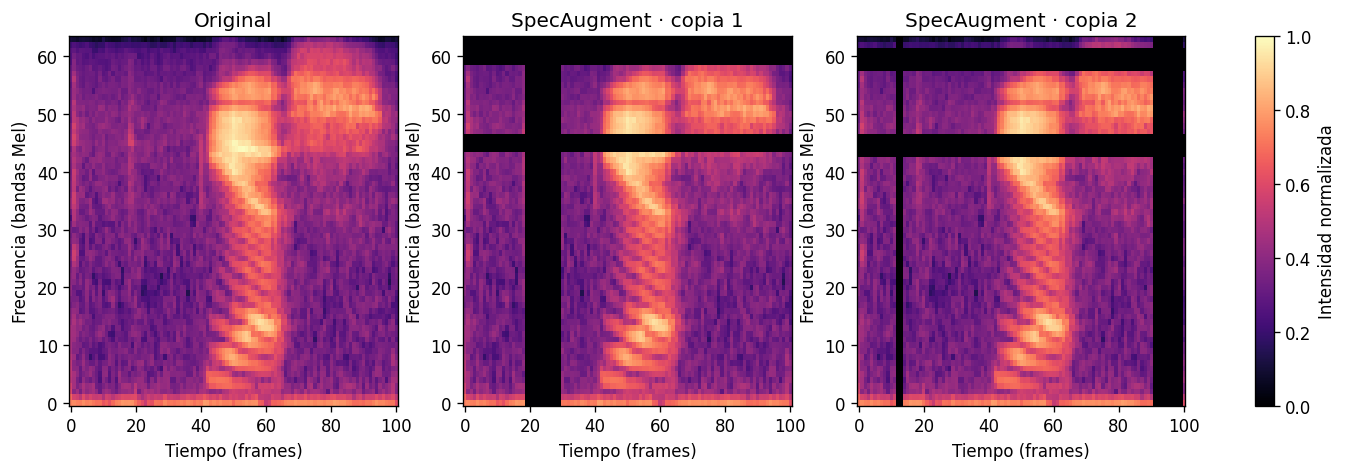

In [21]:
AUGMENTED_DIR = DATA_DIR.with_name(DATA_DIR.name + '-augmented')
subprocess.run([sys.executable, str(AI / 'src/augment.py'), '--data', str(DATA_DIR),
                '--output', str(AUGMENTED_DIR), '--config', str(CONFIG)], cwd=ROOT, check=True)
augmentation = json.loads((AUGMENTED_DIR / 'augmentation.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'dataset': 'base', **augmentation['source_counts']},
                      {'dataset': 'augmented', **augmentation['counts']}]))
display(Image(filename=str(AUGMENTED_DIR / 'preview.png')))

## Revisar la matriz y autenticar

Se selecciona por macro-F1 de validación. Base usa el dataset original y aumentado usa los originales más dos copias guardadas con máscaras temporales y espectrales. `train_clean` mide solo los originales. Validation/test y las particiones por hablante son comunes a todos los trials.

El login de W&B no se guarda en el notebook. En modo offline se registran eventos para sincronizarlos posteriormente.

Los perfiles usan batch 32/64/128 y 15/30/45 épocas completas; también varían LR, weight decay y momentum SGD. Se comparan recetas completas. La tabla muestra experimento, arquitectura, variante, LR, batch y épocas; los demás parámetros siguen en la configuración de entrenamiento.

In [22]:
sys.path.insert(0, str(AI / 'src'))
import importlib
import train
# Releer el entrenador si cambió mientras este kernel seguía abierto.
train = importlib.reload(train)
config = (json.loads((SUITE / 'suite.json').read_text(encoding='utf-8'))['config']
          if (SUITE / 'suite.json').exists() else json.loads(CONFIG.read_text(encoding='utf-8')))
grid = train.experiment_grid(config)
display(pd.DataFrame(grid)[['experiment', 'architecture', 'variant', 'lr', 'batch_size', 'epochs']])
if WANDB_MODE == 'online':
    wandb.login()
elif WANDB_MODE != 'offline':
    raise ValueError('W&B debe estar online u offline')

,experiment,architecture,variant,lr,batch_size,epochs
0,lenet5-base-adam_b32_e15,lenet5,base,0.0010,32,15
1,lenet5-base-adam_b64_e30,lenet5,base,0.0003,64,30
2,lenet5-base-sgd_b128_e45,lenet5,base,0.0200,128,45
3,lenet5-augmented-adam_b32_e15,lenet5,augmented,0.0010,32,15
4,lenet5-augmented-adam_b64_e30,lenet5,augmented,0.0003,64,30
5,lenet5-augmented-sgd_b128_e45,lenet5,augmented,0.0200,128,45
6,mobilenet_v1-base-adam_b32_e15,mobilenet_v1,base,0.0010,32,15
7,mobilenet_v1-base-adam_b64_e30,mobilenet_v1,base,0.0003,64,30
8,mobilenet_v1-base-sgd_b128_e45,mobilenet_v1,base,0.0200,128,45
9,mobilenet_v1-augmented-adam_b32_e15,mobilenet_v1,augmented,0.0010,32,15


## Balance de clases: justificación y protocolo

Los conteos antes de limpieza suman **105.829** ejemplos: `unknown` aporta **67.283 (63,6 %)**, unas **17,5 veces** el tamaño medio de un comando. Predecir siempre `unknown` alcanzaría 63,6 % de accuracy sin reconocer comandos. Los diez comandos ya tienen tamaños similares. La tabla siguiente usa los conteos reales de **train después de la limpieza**, no esos totales iniciales.

Aplicamos **muestreo controlado solo a train** con `sampling.unknown_fraction = 0.20`: aproximadamente **20 % unknown y 80 % comandos**, repartido por igual entre los diez comandos (8 % cada uno). El 20 % es una hipótesis inicial que debe contrastarse con validación; conserva más exposición a unknown que el balance uniforme de once clases (9,1 % cada una), sin dejar que su frecuencia original domine cada época.

Para cada variante, sea `m` el tamaño del comando mayor y `K` el número de comandos. Cada comando recibe `m` ejemplos por época y unknown recibe `round(K * m * p / (1 - p))`, con `p = 0.20`. Se incluyen todos los ejemplos de cada comando antes de repetir los necesarios para completar su cuota. Para unknown se selecciona una nueva muestra aleatoria cada época, estratificada **proporcionalmente por `source_label`** para conservar la variedad de palabras del corpus; se evita repetición mientras alcanza su reserva. Los índices se mezclan antes de formar batches. **Las cuotas son por época, no exactas por minibatch**, y el redondeo puede cambiar ligeramente el porcentaje en datasets pequeños. Selecciones de distintas épocas pueden solaparse; no se garantiza recorrer todo unknown en un número fijo de épocas.

Usamos **cross-entropy sin pesos de clase** (`class_weighting = 'none'`): el muestreo ya modifica la exposición a cada clase. Combinarlo con pesos de frecuencia inversa sobre los conteos originales corregiría dos veces el desbalance. La configuración rechaza esa combinación. Como alternativas para otra suite: `unknown_fraction = 1 / 11` prueba balance uniforme; `sampling.strategy = 'none'` junto con `class_weighting = 'inverse_frequency'` permite comparar la estrategia anterior. Elegir estas opciones usando validación, antes de abrir test.

El dataset base y el aumentado conservan sus archivos. En el aumentado las cuotas se calculan sobre originales y copias guardadas; su presupuesto por época es aproximadamente tres veces el de base. Se registran tanto `training_samples` (almacenados) como `samples_per_epoch` (muestreados) y `optimizer_steps`. El generador del sampler comparte el estado RNG del DataLoader y usa la semilla de la suite para reproducir el muestreo al entrenar desde el inicio en el mismo entorno.

La partición por hablante ocurre **antes** del muestreo y del aumento. `train_clean`, validation y test recorren sus particiones originales completas, sin balanceo ni aumento. Su distribución representa el corpus; no garantiza representar el uso real de un reconocedor continuo. Elegimos checkpoints por **macro-F1 de validación** y reportamos balanced accuracy, precision/recall/F1 por clase y matrices de confusión. Reducir unknown puede mejorar recall de comandos y aumentar activaciones incorrectas: revisar ambos tipos de error en la celda de diagnóstico, sin seleccionar por accuracy global ni ajustar con test. Cambiar el muestreo también cambia la distribución aprendida; cualquier umbral de rechazo debe validarse con datos representativos del uso esperado.

Se inicia una **suite nueva** para esta receta; los checkpoints anteriores conservan su configuración e identidad de código y no se mezclan con los nuevos.

Referencias: [TensorFlow: sampling y class weights](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data), [PyTorch: Sampler y DataLoader](https://docs.pytorch.org/docs/stable/data.html), [scikit-learn: balanced accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).


,class,train_original,base_por_epoca,augmented_por_epoca
0,yes,3125,3125,9375
1,no,3048,3125,9375
2,left,2991,3125,9375
3,right,2940,3125,9375
4,up,2889,3125,9375
5,down,3064,3125,9375
6,on,3013,3125,9375
7,off,2913,3125,9375
8,stop,3040,3125,9375
9,go,3041,3125,9375


,variant,stored_samples,strategy,samples_per_epoch,unknown_fraction_actual
0,base,83150,controlled,39062,0.199990
1,augmented,249450,controlled,117188,0.200003


,unknown_base_por_epoca
backward,190
bed,232
bird,247
cat,242
dog,251
eight,436
five,468
follow,182
forward,180
four,426


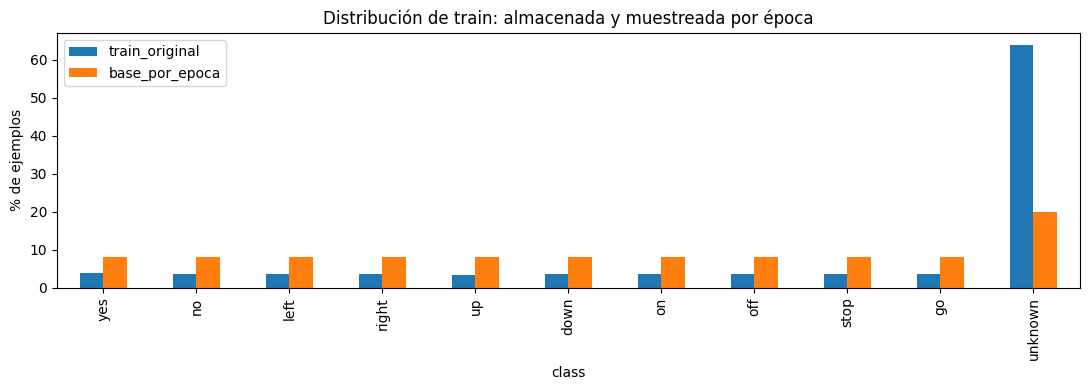

Vista previa de la política común a los trials; cuotas efectivas guardadas por experimento en sampling.json.


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from data import SpectrogramDataset
from sampling import make_training_loader

classes = json.loads((DATA_DIR / 'preprocessing.json').read_text(encoding='utf-8'))['classes']
original_train = SpectrogramDataset(DATA_DIR, 'train')
available = np.bincount(original_train.y, minlength=len(classes))
sampling_preview = pd.DataFrame({'class': classes, 'train_original': available})
sampling_plans = []
for variant, root in [('base', DATA_DIR), ('augmented', AUGMENTED_DIR)]:
    dataset_preview = SpectrogramDataset(root, 'train')
    loader_preview = make_training_loader(dataset_preview, classes, grid[0])
    if hasattr(loader_preview.sampler, 'summary'):
        plan = loader_preview.sampler.summary()
        quotas = [plan['class_quotas'][label] for label in classes]
    else:
        quotas = np.bincount(dataset_preview.y, minlength=len(classes)).tolist()
        plan = {'strategy': 'none', 'samples_per_epoch': len(dataset_preview)}
    sampling_preview[f'{variant}_por_epoca'] = quotas
    sampling_plans.append({'variant': variant, 'stored_samples': len(dataset_preview), **plan})
display(sampling_preview)
display(pd.DataFrame(sampling_plans).drop(columns=['class_quotas', 'unknown_word_quotas'], errors='ignore'))
if 'unknown_word_quotas' in sampling_plans[0]:
    display(pd.Series(sampling_plans[0]['unknown_word_quotas'], name='unknown_base_por_epoca').to_frame())
fractions = sampling_preview.set_index('class')[['train_original', 'base_por_epoca']]
fractions = fractions.div(fractions.sum()).mul(100)
fractions.plot.bar(figsize=(11, 4), ylabel='% de ejemplos', title='Distribución de train: almacenada y muestreada por época')
plt.tight_layout()
plt.show()
print('Vista previa de la política común a los trials; cuotas efectivas guardadas por experimento en sampling.json.')


## Entrenar UN experimento completo

Esta celda no usa `--all`. Con `EXPERIMENT=None`, reejecutarla inicia el primer trial pendiente. Indicar un nombre permite elegir otro; los completos se omiten.

Cada trial se entrena de corrido durante todas sus épocas configuradas, sin early stopping, en un único run W&B. El mejor modelo por validación se conserva en memoria y se guarda como `best.pt` solo al terminar. Se siguen registrando métricas por época. Si se interrumpe, ese trial se reinicia desde la época uno; los trials completos se conservan.


In [ ]:
EXPERIMENT = 'lenet5-base-adam_b32_e15'  # None = siguiente pendiente; o 'lenet5-base-adam_b32_e15'
def execute(command):
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                          env={**os.environ, 'PYTHONIOENCODING': 'utf-8'}) as process:
        try:
            for line in process.stdout:
                print(line, end='', flush=True)
            if process.wait() != 0:
                raise RuntimeError('Falló el comando; el progreso guardado se conserva')
        except KeyboardInterrupt:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            print('Interrumpido: este trial reiniciará desde la época uno. Los trials completos se conservan.')
            raise

command = [sys.executable, str(AI / 'src/train.py'), '--suite', str(SUITE), '--watch']
if not (SUITE / 'suite.json').exists():
    command += ['--data', str(DATA_DIR), '--config', str(CONFIG), '--project', PROJECT,
                '--wandb-mode', WANDB_MODE, '--device', DEVICE]
    if ENTITY:
        command += ['--entity', ENTITY]
if EXPERIMENT:
    command += ['--experiment', EXPERIMENT]
execute(command)
execute([sys.executable, str(AI / 'src/train.py'), '--suite', str(SUITE), '--list'])

Suite: D:\Repos\OnnxMobile\ai\runs\speech_commands_gpu_fixed_epochs_v5
Device: cuda
Complete: 0/12
This invocation: 1
Train samples: base=83150, augmented=249450
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\danie\_netrc.
wandb: Currently logged in as: danielpulido (danielpulido-instituto-tecnol-gico-de-costa-rica) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run dgqedvqk
wandb: Tracking run with wandb version 0.29.0
wandb: Run data is saved locally in D:\Repos\OnnxMobile\ai\runs\speech_commands_gpu_fixed_epochs_v5\wandb\run-20261014_140358-dgqedvqk
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run lenet5-base-adam_b64_e30
wandb:  View project at https://wandb.ai/danielpulido-instituto-tecnol-gico-de-costa-rica/onnxmobile-speech-commands
wandb:  View run at https://wandb.ai/danielpulido-instituto-tecnol-gico-de-costa-rica/onnxmobi

## Resultados acumulados

La tabla incorpora todos los trials completos, aunque se ejecuten en días distintos. Las curvas se guardan al finalizar cada trial. Compare train_clean con validación para discutir ajuste. Los ganadores se fijan cuando se completan los doce experimentos.

In [ ]:
if (SUITE / 'training_results.csv').exists():
    display(pd.read_csv(SUITE / 'training_results.csv'))
else:
    print('Todavía no hay trials completos; el checkpoint se guarda al terminar cada entrenamiento.')
for item in grid:
    path = SUITE / item['experiment'] / 'learning_curves.png'
    if path.exists():
        print(item['experiment'])
        display(Image(filename=str(path)))
if (SUITE / 'selection.json').exists():
    selection = json.loads((SUITE / 'selection.json').read_text(encoding='utf-8'))
    display(pd.DataFrame(selection['winners'].values()))
    print('Mejor global por validación:', selection['best_overall'])
    print('Mejor base por validación:', selection['best_base'])
else:
    print('Se fijarán los cuatro ganadores cuando se completen los doce experimentos.')

## Test, en otra sesión si se prefiere

La evaluación se habilita con `RUN_TEST=True` después de completar los doce trials. Por defecto esta celda solo muestra resultados existentes. Test no decide hiperparámetros ni checkpoints. La evaluación conserva los resultados de cada ganador si se interrumpe.

In [ ]:
if RUN_TEST and not (SUITE / 'selection.json').exists():
    raise RuntimeError('Primero complete los doce experimentos y la selección por validación')
if RUN_TEST and not (SUITE / 'test_results.json').exists():
    execute([sys.executable, str(AI / 'src/evaluate.py'), '--suite', str(SUITE)])
if (SUITE / 'test_results.json').exists():
    display(pd.read_csv(SUITE / 'test_results.csv'))
    report_path = SUITE / 'report.ipynb'
    if report_path.exists():
        report = json.loads(report_path.read_text(encoding='utf-8'))
        for report_cell in report['cells']:
            if report_cell['cell_type'] == 'markdown':
                display(Markdown(''.join(report_cell['source'])))
else:
    print('Test pendiente; RUN_TEST=False conserva esta fase para otra sesión.')
print('Artefactos:', SUITE)
print('W&B: agrupar los runs por', SUITE.name)

## Diagnóstico: comandos rechazados y activaciones de unknown

La matriz usa filas reales y columnas predichas. La tabla muestra precision/recall/F1 por clase del mejor checkpoint, macro-F1 y balanced accuracy. Dos tasas complementarias explican el compromiso del muestreo:

- **Unknown → comando**: unknown predichos como cualquier comando / total real de unknown. Mide activaciones incorrectas por clip de palabra desconocida.
- **Comando → unknown**: comandos predichos como unknown / total real de comandos. No incluye confusiones entre dos comandos, visibles en la matriz y las métricas por clase.

Estas tasas no equivalen a falsas activaciones por hora de audio continuo. Revisar primero validación; test se muestra solo cuando ya existe la evaluación autorizada por `RUN_TEST`.


In [ ]:
from metrics import metrics_from_confusion

unknown_id = classes.index('unknown')
error_rows = []
for item in grid:
    for split, filename in [('validation', 'validation_best_confusion.csv'), ('test', 'test_confusion.csv')]:
        path = SUITE / item['experiment'] / filename
        if not path.exists():
            continue
        confusion = np.loadtxt(path, delimiter=',', dtype=np.int64)
        metrics = metrics_from_confusion(confusion)
        unknown_total = int(confusion[unknown_id].sum())
        command_total = int(confusion.sum()) - unknown_total
        false_commands = unknown_total - int(confusion[unknown_id, unknown_id])
        rejected_commands = int(confusion[:, unknown_id].sum()) - int(confusion[unknown_id, unknown_id])
        error_rows.append({'experiment': item['experiment'], 'split': split,
                           'macro_f1': metrics['macro_f1'], 'balanced_accuracy': metrics['balanced_accuracy'],
                           'unknown_to_command': false_commands / unknown_total if unknown_total else float('nan'),
                           'command_to_unknown': rejected_commands / command_total if command_total else float('nan')})
        print(item['experiment'], '|', split)
        display(pd.DataFrame(metrics['per_class'], index=pd.Index(classes, name='class')))
        display(pd.DataFrame(confusion, index=pd.Index(classes, name='real'), columns=pd.Index(classes, name='predicha')))
if error_rows:
    display(pd.DataFrame(error_rows))
else:
    print('Sin checkpoints completos: el diagnóstico estará disponible al terminar un trial.')


# Guía de ejecución y recuperación

El protocolo completo y los diagramas están en las celdas anteriores. La matriz reproducible está en
[experiments.json](../configs/experiments.json). Las redes manuales están en
[models.py](../src/models.py). No hay resultados reales de entrenamiento incluidos
en el repositorio: las tablas e informes se calculan al ejecutar los experimentos.

## Instalar y conectar W&B

Desde `D:\Repos\OnnxMobile`, en PowerShell:

```powershell
.\.venv\Scripts\python.exe -m pip install -r ai/requirements.txt
.\.venv\Scripts\wandb.exe login
```

El login solicita la clave fuera del código. También se puede configurar
`WANDB_API_KEY` en el entorno, sin guardarla en Git/notebooks. El proyecto por
defecto es `onnxmobile-speech-commands`; `--entity` permite seleccionar una cuenta
o equipo y `--project` otro nombre. El modo predeterminado es online, para ver
el comportamiento en vivo en W&B. Todas las fases registran runs W&B.

Si el login dice que la clave debe tener 40 caracteres pero la plataforma entrega
una clave de 86 caracteres, comprobar que el cliente instalado sea la versión
fijada actual (0.29.0). El cliente anterior 0.19.11 rechazaba ese formato por su
validación de longitud. Actualizar y pegar la clave completa en el prompt:

```powershell
.\.venv\Scripts\python.exe -m pip install --upgrade wandb==0.29.0
.\.venv\Scripts\wandb.exe login --relogin --verify
```

Reiniciar el kernel de Jupyter si estaba abierto durante la actualización.
La cuenta personal en CoreWeave Forge usa el login del SDK W&B; no configurar
la página `/wandb/home` como `WANDB_BASE_URL`.

Para la GTX 1650 y un driver compatible con CUDA 12.1 se puede instalar la rueda
CUDA de la misma versión fijada de PyTorch:

```powershell
.\.venv\Scripts\python.exe -m pip install torch==2.5.1 --index-url https://download.pytorch.org/whl/cu121
.\.venv\Scripts\python.exe -c "import torch; print(torch.__version__, torch.cuda.is_available())"
```

Si ya hay instalada una rueda CPU de la misma versión, añadir `--force-reinstall`
para cambiarla por la rueda CUDA. El driver detectado al implementar fue 551.23;
la disponibilidad real se comprueba con `torch.cuda.is_available()`. El CLI usa
CUDA si está disponible y CPU en otro caso; `--device cuda` exige GPU y falla si
no está disponible. Registrar la versión exacta de la rueda con el experimento.

## Un entrenamiento por sesión

La receta predeterminada usa `sampling.strategy: controlled`,
`unknown_fraction: 0.20` y `class_weighting: none`. Por época, cada comando recibe
tantos ejemplos como el comando mayor y unknown completa aproximadamente el 20 %
del total. Se selecciona un nuevo subconjunto de unknown por época, proporcional
a sus palabras de origen; se recorren los comandos antes de repetir para completar
cuotas. Las cuotas no son exactas por batch. Validation, test y train limpio
conservan todos sus ejemplos originales. El notebook 02 incluye la justificación,
tablas y gráfico del muestreo, métricas por clase y tasas de unknown → comando y
comando → unknown. El porcentaje es una hipótesis inicial que se contrasta con
validación, sin ajustar con test.

Usar una suite nueva, por ejemplo `speech_commands_gpu_fixed_epochs_v5`
(predeterminada en el notebook), para esta política. Los checkpoints anteriores
no son compatibles con el nuevo código. Los datasets almacenados se reutilizan;
no hace falta regenerar espectrogramas. Cada trial se entrena de corrido y su
mejor modelo por validación se guarda únicamente cuando termina.

Usar una exportación con `COMPLETED.json` y once clases. Por ejemplo:

```powershell
.\.venv\Scripts\python.exe ai/src/train.py --data ai/data/processed/speech_commands/20261008T020826106877Z --suite ai/runs/speech_commands_gpu_fixed_epochs_v5 --project onnxmobile-speech-commands --watch
```

La primera invocación prepara los dos datasets, sin modificar el original. Por
defecto crea una carpeta hermana con sufijo `-augmented`, verificada y reutilizada
en las siguientes sesiones. Para generarla **sin iniciar ningún entrenamiento**:

```powershell
.\.venv\Scripts\python.exe ai/src/augment.py --data ai/data/processed/speech_commands/20261008T020826106877Z
```

`--output RUTA` permite otra ubicación al exportar; indicar esa misma carpeta con
`train.py --augmented-data RUTA` al crear la suite. La suite recuerda ambas rutas.
Se usa `augmentation` de `experiments.json` y la semilla de la suite + 1000;
ambos scripts aceptan `--config` para una política diferente. Una exportación
existente solo se reutiliza si coinciden origen, política, semilla y hashes;
no se sobrescribe. Para otra política, elegir otra carpeta y una suite nueva.

Con `copies_per_sample: 2`, train base conserva **83.150** ejemplos y train
aumentado guarda **249.450**: originales más dos copias con time masking y
frequency masking. El ejemplo de 100 → 300 se refiere solo a entrenamiento.
Validation (**9.962**) y test (**10.730**) son los mismos archivos originales
para todos los modelos. Los nuevos tensores ocupan unos **6,45 GB** adicionales.
No se generan nuevos WAV: las técnicas se aplican al espectrograma log-Mel.

La carpeta aumentada contiene `X_train.npy`, `y_train.npy`, `manifest.csv`,
`augmentation.json`, `preview.png` y `COMPLETED.json`. El manifiesto registra
`source_tensor_index`, `augmentation_copy` (0 = original) y `technique`, además
de hablante, clase y hashes del audio fuente. No contiene copias de validation/test:
se leen del dataset original indicado en `augmentation.json`.

Agregar `--entity NOMBRE_EQUIPO` si aplica. Este comando ejecuta **un solo trial**,
de 15, 30 o 45 épocas según el perfil, con validación y sin early stopping.
La misma carpeta `--suite`
reúne los doce experimentos, aunque se ejecuten en días distintos. Sin seleccionar
un nombre, se inicia el primer trial pendiente en el orden de la matriz.
`--workers 0` es portable en Windows;
se puede fijar otro número antes de iniciar la comparación. Los modelos deben
usar el mismo entorno y particiones durante toda la suite.

Para iniciar el siguiente trial, basta repetir:

```powershell
.\.venv\Scripts\python.exe ai/src/train.py --suite ai/runs/speech_commands_gpu_fixed_epochs_v5 --watch
```

Se infieren los datos, configuración, proyecto, entidad, dispositivo y modo W&B
de la suite. Los trials completos se conservan y no se vuelven a entrenar.
Para consultar el estado sin entrenar ni conectar W&B, o elegir un trial:

```powershell
.\.venv\Scripts\python.exe ai/src/train.py --suite ai/runs/speech_commands_gpu_fixed_epochs_v5 --list
.\.venv\Scripts\python.exe ai/src/train.py --suite ai/runs/speech_commands_gpu_fixed_epochs_v5 --experiment mobilenet_v1-augmented-adam_b32_e15 --watch
```

`--list` muestra `complete` o `pending`. Seleccionar un trial completo
lo omite. El flag opcional `--all` permite ejecutar explícitamente todos los
pendientes; no es el comportamiento predeterminado.

La matriz actual está en [experiments.json](../configs/experiments.json):

| Perfil | Batch | Épocas | LR | Weight decay | Momentum SGD |
| --- | ---: | ---: | ---: | ---: | ---: |
| `adam_b32_e15` | 32 | 15 | 0,001 | 0 | — |
| `adam_b64_e30` | 64 | 30 | 0,0003 | 0,0001 | — |
| `sgd_b128_e45` | 128 | 45 | 0,02 | 0,0005 | 0,95 |

`epochs` dentro de cada trial reemplaza el default global.
Cada invocación completa todas las épocas del trial. La tabla de resultados
guarda `epochs`, `epochs_ran` y `momentum`, además de LR, batch y regularización.
Los parámetros `patience` y `min_delta` se eliminaron junto con early stopping.

Para estos perfiles usar una suite nueva, por ejemplo
`speech_commands_gpu_fixed_epochs_v5` (el notebook ya selecciona su variante GPU).
Las suites existentes conservan su configuración guardada y sus resultados.
El nuevo código requiere una suite nueva porque cambió su huella de código. No editar una suite iniciada para aplicar
los nuevos perfiles. Ambos datasets se reutilizan, porque la política de aumento
y la semilla permanecen iguales.

Se imprimen la carpeta de la suite y las métricas de cada época.
En W&B, agrupar por el nombre de esa carpeta y filtrar `job_type=train`: estarán los runs
con tags de arquitectura y variante. Graficar `train/loss`, `train_clean/loss`,
`validation/loss`, `train_clean/macro_f1`, `validation/macro_f1` contra `epoch`.
`--watch` agrega histogramas de parámetros/gradientes cada 100 pasos; tiene costo
adicional. Al completar los doce trials, la fase de comparación sube las tablas
y fija los cuatro ganadores. No se hace selección final ni test con una matriz
incompleta. El contrato del modelo usa las clases en `preprocessing.json`, sin
reordenarlas alfabéticamente.

También se puede seguir el flujo en
[02_entrenamiento_evaluacion.ipynb](02_entrenamiento_evaluacion.ipynb).
Ese notebook ejecuta los mismos scripts y muestra sus artefactos; no duplica
rutinas de entrenamiento. Al ejecutar todas sus celdas se entrena un solo trial.
`EXPERIMENT=None` elige el siguiente pendiente; indicar un nombre selecciona uno.
El test permanece separado con
`RUN_TEST=False` hasta que el usuario lo habilite después de completar la matriz.

## Evaluar los cuatro ganadores

Una vez finalizados los doce trials, reemplazar `<SUITE>` por la carpeta impresa:

```powershell
.\.venv\Scripts\python.exe ai/src/evaluate.py --suite ai/runs/<SUITE>
```

Se cargan exclusivamente los checkpoints elegidos por validación, se evalúan
en el mismo test sin aumento y se registran cuatro runs W&B de test. No se usa
test para búsqueda ni para cambiar el ganador. Si el test ya
terminó, el script pide reutilizar los resultados guardados. El informe final
se sube a W&B como artefacto junto con las tablas. La latencia comparativa es
CPU PyTorch, batch=1; no equivale a rendimiento móvil ni incluye preprocesamiento.

## Artefactos locales

| Archivo | Contenido |
| --- | --- |
| `suite.json`, `dataset.json`, `augmented_dataset.json` | Configuración, identidad de código y de ambos datasets, rutas y hashes |
| `<experimento>/config.json` | Hiperparámetros explícitos |
| `<experimento>/sampling.json` | Cuotas por clase y palabra unknown, total muestreado por época |
| `<experimento>/environment.json`, `requirements-lock.txt` | Entorno y versiones |
| `<experimento>/architecture.txt` | Capas del modelo real |
| `<experimento>/history.csv`, `learning_curves.png` | Curvas de train, train limpio y validation |
| `<experimento>/best.pt` | Mejor modelo por validación, optimizador, clases y pesos; se escribe solo al finalizar el entrenamiento |
| `<experimento>/validation_best_confusion.*` | Matriz de validación del mejor checkpoint |
| `training_results.csv` | Resultados de los doce entrenamientos |
| `selection.json` | Cuatro ganadores y mejores global/base, fijados antes de test |
| `<experimento>/test_result.json`, `test_confusion.*` | Métricas por clase y matriz de test |
| `test_results.csv`, `test_results.json`, `report.ipynb` | Comparación e insumos para el informe |
| `wandb/` | Eventos locales del SDK de W&B |

Los trials `base` leen el train original; los `augmented` leen el train expandido
guardado, sin aplicar máscaras adicionales durante la época. `train_clean`
siempre evalúa únicamente los originales. Validación y test son comunes a las
dos variantes, sin fuga de copias del mismo audio a otras particiones.
La tabla registra `training_samples` (almacenados), `original_training_samples`,
`samples_per_epoch` (muestreados), `sampling_strategy` y `optimizer_steps`.
Con igual límite de épocas el dataset aumentado permite más
pasos de optimización: el informe explicita este presupuesto y muestra diferencias
de macro-F1 por arquitectura con los mismos hiperparámetros, además del test de
los ganadores. Un delta positivo indica mejora y uno negativo deterioro en esa
ejecución; no demuestra significancia estadística.

Las suites anteriores usaban aumento dinámico y no son compatibles con este
protocolo de exportación fija. Conservarlas y usar una carpeta `--suite` nueva;
los controles de identidad impiden mezclar sus checkpoints con los nuevos.

## Checkpoint final y entrenamientos interrumpidos

Cada trial se ejecuta de corrido durante todas las épocas de su perfil (15, 30 o
45), sin early stopping. No hay pausas cada cinco épocas. Se registran las
métricas en W&B y `history.csv` después de cada época; el mejor modelo por
macro-F1 de validación (menor loss en caso de empate) se conserva en memoria.

Al terminar el entrenamiento se escribe `best.pt` una sola vez, atómicamente:
primero un temporal, luego se vacía a disco y se reemplaza el destino. El archivo
conserva los pesos de la mejor época, que puede ser anterior a la última. No se
crea `last.pt` ni se recuperan entrenamientos parciales.

Si falla o se interrumpe el proceso, repetir el comando reinicia el trial pendiente
desde la época uno. Los trials que ya tienen `result.json` se omiten y sus
checkpoints se conservan. Cada entrenamiento completo usa un único run W&B;
un intento interrumpido puede quedar como run fallido en W&B, pero no se publica
un artefacto de modelo parcial.

Para continuar con el siguiente trial se reutiliza `--suite`. La suite exige el
mismo código, datos y configuración; usar una suite nueva para este cambio:
`speech_commands_gpu_fixed_epochs_v5`. Los archivos de las suites anteriores
se conservan y los datasets almacenados se reutilizan. `--resume-suite` sigue
siendo un alias de `--suite` para continuar la matriz de experimentos.
Un bloqueo del sistema operativo impide dos entrenamientos simultáneos en la
misma suite y se libera si el proceso muere.


## Trabajar sin conexión

Para máquinas sin Internet, agregar `--wandb-mode offline` al entrenamiento.
La evaluación hereda el mismo modo. Los eventos se guardan mediante el SDK W&B
y se suben después; hasta entonces no hay tablero web. Tras conectar/login:

```powershell
Get-ChildItem -LiteralPath ai/runs/<SUITE>/wandb -Directory -Filter 'offline-run-*' | ForEach-Object { .\.venv\Scripts\python.exe -m wandb sync $_.FullName }
```

Esto sincroniza también los runs de comparación, test e informe, además de los
doce de entrenamiento. No se ofrece un modo sin tracking.

## Verificación técnica sin entrenar el corpus

```powershell
.\.venv\Scripts\python.exe -m unittest discover -s ai/tests -v
```

Las pruebas de entrenamiento verifican gradientes de ambas arquitecturas,
parámetros/conectividad de LeNet, repetibilidad, enmascaramiento, ausencia de
aumento en eval, métricas, agregación de loss ponderada, auditoría de hablantes
y selección por validación. La prueba integral ejecuta **12 trials sintéticos de
una o dos épocas**, con overrides por perfil, `--all` explícito y test de cuatro
ganadores con eventos W&B offline.
También verifica que el checkpoint solo se escriba al finalizar (incluido early
stopping), que una interrupción no guarde pesos parciales y que cada trial
completo use un único run W&B. Comprueba que repetir un trial completo no lo
modifique, que el modo predeterminado entrene solo uno y que una escritura fallida
preserve el checkpoint previo.
Sus carpetas son temporales: no son resultados experimentales del corpus real.

## Dataset compartido

La descarga, verificación, empaquetado y atribución están documentados en las celdas del [notebook de exploración](01_exploracion_speech_commands.ipynb).